# Notebook 1 · Deep learning: benign vs malignant mammograms

The project has three files:

| File | Content |
|---|---|
| **`1_deep_learning.ipynb`**  | Find the data, split it, train the ResNet18 model, evaluate it |
| `2_classical_ml.ipynb` | Baseline, SVM and Random Forest, then compare all models |
| `3_flask_app` | A web page where you upload a mammogram and see the prediction |

Steps in this notebook, built one at a time:

| Step | What we do |
|---|---|
| 1 | Find and inspect the images |
| **2** | **Split into train / validation / test** |
| 3 | Train the deep learning model (transfer learning) |
| 4 | Evaluate it on the test set |

## Step 1 · Find and inspect the images

**What:** scan the `images` folder and build a table with one row per mammogram (file path, label, patient, view).
**Why:** every later step needs this table, and we must be sure we only use real mammograms. The folders also contain mask files, overlay files and metadata that are *not* training images.

In [23]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
IMAGES_DIR = Path("MINI-DDSM-Complete-JPEG-8")    # the folder containing Benign/ and Cancer/
print("Looking in:", IMAGES_DIR.resolve())
print("Folder exists:", IMAGES_DIR.exists())

Looking in: D:\BS CS AI\5th Semester\Machine Learning\Project\MINI-DDSM-Complete-JPEG-8
Folder exists: True


**Build the table.** We keep only `.jpg` files inside a `Benign` or `Cancer` folder, and skip anything with `Mask` in its name (those are outlines of the tumour, drawn after diagnosis, so using them would leak data).

In [24]:
rows = []
for p in sorted(IMAGES_DIR.rglob("*.jpg")):
    if "mask" in p.name.lower():
        continue                              # skip tumour-outline masks
    folder = p.parent.parent.name             # Benign, Cancer or Normal
    if folder not in ["Benign", "Cancer"]:
        continue                              # skip Normal/
    rows.append({
        "path": p.as_posix(),
        "label": 0 if folder == "Benign" else 1,     # 0 = benign, 1 = cancer
        "class_name": folder,
        "patient": folder + "_" + p.parent.name,     # e.g. Benign_0029
        "view": p.stem.split(".")[-1],               # e.g. LEFT_CC
    })

df = pd.DataFrame(rows)
print(f"{len(df)} images found")
print(df.class_name.value_counts())   # count of each class
df.head()

5400 images found
class_name
Cancer    2716
Benign    2684
Name: count, dtype: int64


,path,label,class_name,patient,view
0,MINI-DDSM-Complete-JPEG-8/Benign/0029/C_0029_1...,0,Benign,Benign_0029,LEFT_CC
1,MINI-DDSM-Complete-JPEG-8/Benign/0029/C_0029_1...,0,Benign,Benign_0029,LEFT_MLO
2,MINI-DDSM-Complete-JPEG-8/Benign/0029/C_0029_1...,0,Benign,Benign_0029,RIGHT_CC
3,MINI-DDSM-Complete-JPEG-8/Benign/0029/C_0029_1...,0,Benign,Benign_0029,RIGHT_MLO
4,MINI-DDSM-Complete-JPEG-8/Benign/0033/C_0033_1...,0,Benign,Benign_0033,LEFT_CC


Expected: 2,684 Benign and 2,716 Cancer images.

In [25]:
print(df.groupby("class_name").agg(images=("path", "size"), patients=("patient", "nunique")))
print()
print("Images per patient:")
print(df.groupby("patient").size().value_counts().sort_index())

            images  patients
class_name                  
Benign        2684       671
Cancer        2716       679

Images per patient:
4    1350
Name: count, dtype: int64


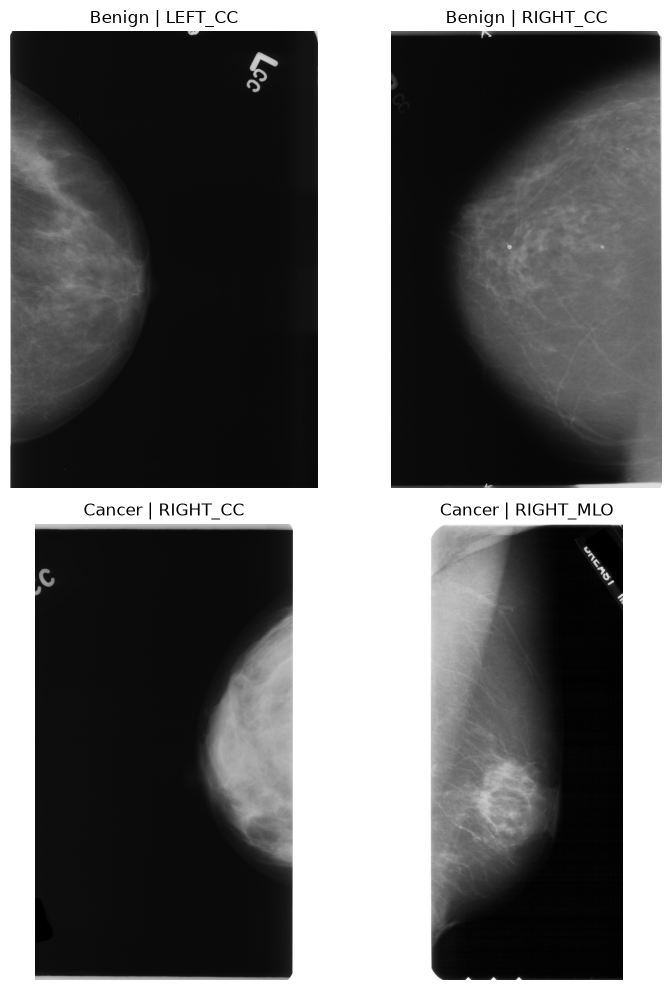

In [26]:
# 2 random benign and 2 random cancer images
samples = pd.concat([df[df.label == 0].sample(2, random_state=SEED),
                     df[df.label == 1].sample(2, random_state=SEED)])

fig, axes = plt.subplots(2, 2, figsize=(8, 10))
for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    ax.imshow(Image.open(row.path).convert("L"), cmap="gray")
    ax.set_title(f"{row.class_name} | {row.view}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Check image sizes.** Neural networks need every image to be the same size, so we will resize them.

In [27]:
sample = df.sample(200, random_state=SEED)
sizes = [Image.open(p).size for p in sample.path]
widths = [s[0] for s in sizes]
heights = [s[1] for s in sizes]
print(f"width : {min(widths)} to {max(widths)} pixels")
print(f"height: {min(heights)} to {max(heights)} pixels")

width : 916 to 2521 pixels
height: 1981 to 3436 pixels


## Step 2 · Split into train / validation / test

**What:** divide the data into three groups, 80% / 10% / 10%.

| Group | Used for |
|---|---|
| **train** | the model learns from these images |
| **validation** | during training: decide when to stop, and later choose the decision threshold |
| **test** | the final exam: used **once**, at the very end, to report honest results |


**Why we split by *patient*, not by image:** one patient has up to 4 images (left/right breast, CC/MLO view) that look alike. If we split by image, the left breast of a patient could be in training and the right breast in the test set. The model would then partly recognise the *patient*, not the disease, and the test score would look better than it really is. So all images of one patient go to the same group.

**How:** split the list of patients (keeping the benign/cancer ratio equal in each group), then give every image the group of its patient. The seed is fixed so the split is the same every time.

In [28]:
from sklearn.model_selection import train_test_split

# one row per patient with its label
patients = df.groupby("patient").label.first().reset_index()

# 10% of the patients go to test
trainval, test = train_test_split(patients, test_size=0.10, stratify=patients.label, random_state=SEED)

# 10% of all patients go to validation (that is 1/9 of the patients left)
train, val = train_test_split(trainval, test_size=1/9, stratify=trainval.label, random_state=SEED)

# every image gets the group of its patient
df["split"] = "train"
df.loc[df.patient.isin(val.patient), "split"] = "val"
df.loc[df.patient.isin(test.patient), "split"] = "test"

**Check the split.** Sizes should be close to 80/10/10 and the Benign/Cancer mix similar in every group. The last line proves no patient is in two groups.

In [29]:
groups = ["train", "val", "test"]

print("Images per group and class:")
print(df.groupby(["split", "class_name"]).size().unstack().loc[groups])
print()
print("Share of images in each group (%):")
print((df.split.value_counts(normalize=True).loc[groups] * 100).round(1))
print()
# must be 0: no patient may be in two groups
print("Patients in more than one group:", (df.groupby("patient").split.nunique() > 1).sum())

Images per group and class:
class_name  Benign  Cancer
split                     
train         2148    2172
val            268     272
test           268     272

Share of images in each group (%):
split
train    80.0
val      10.0
test     10.0
Name: proportion, dtype: float64

Patients in more than one group: 0


**Save the split.** The classical ML notebook and the Flask app must use exactly the same train/validation/test groups, so we save them to a file.

In [ ]:
df.to_csv("data_split.csv", index=False)
print("Saved data_split.csv with", len(df), "rows")

## Step 3 · Train the deep learning model

We use ResNet18, a neural network that is already trained on millions of normal photos. We keep what it learned and train only a new last layer for benign vs cancer. This is called transfer learning.

Parts: 3.1 resize the images, 3.2 load them for training, 3.3 build the model, 3.4 train it, 3.5 save it.

### 3.1 Resize the images

The original images are huge (about 2000 x 3000 pixels). We resize all of them once to 224 x 224 grey images and save them in one file, so training does not have to open 5,400 big JPEG files every time. Row i in this file is row i in `data_split.csv`.

In [30]:
import numpy as np

IMG_SIZE = 224

def load_image(path):
    img = Image.open(path)
    img.draft("L", (IMG_SIZE, IMG_SIZE))              # makes loading big JPEGs faster
    img = img.convert("L").resize((IMG_SIZE, IMG_SIZE))
    return np.array(img)

images = np.zeros((len(df), IMG_SIZE, IMG_SIZE), dtype=np.uint8)
for i, path in enumerate(df.path):
    images[i] = load_image(path)
    if i % 500 == 0:
        print(i, "of", len(df))

np.save("images_224.npy", images)
print("Saved images_224.npy with shape", images.shape)

0 of 5400
500 of 5400
1000 of 5400
1500 of 5400
2000 of 5400
2500 of 5400
3000 of 5400
3500 of 5400
4000 of 5400
4500 of 5400
5000 of 5400
Saved images_224.npy with shape (5400, 224, 224)


Checking that the first resized image looks right.

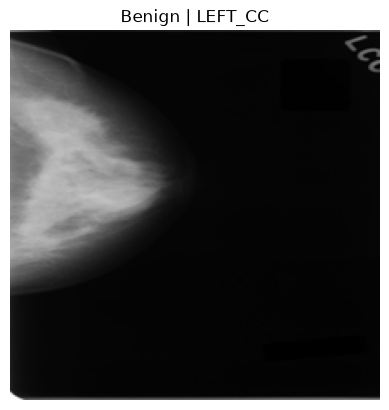

In [31]:
plt.imshow(images[0], cmap="gray")
plt.title(df.class_name[0] + " | " + df.view[0])
plt.axis("off")
plt.show()

### 3.2 Connect to Drive

On Colab we connect to Google Drive so the notebook can find `images_224.npy` and `data_split.csv`. On the laptop this cell just does nothing.

In [8]:
import os

try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/mammogram")
except ImportError:
    print("Not on Colab, using the current folder")

import torch
print("GPU available:", torch.cuda.is_available())
print("Current folder:", os.getcwd())
print("Files here:", os.listdir())

import torch
print("GPU available:", torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU available: True
Current folder: /content/drive/MyDrive/mammogram
Files here: ['data_split.csv', 'deep_learning.ipynb', 'images_224.npy']
GPU available: True


### 3.3 Load the data

We load the saved images and the split file, then separate the images into train, validation and test using the `split` column.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

df = pd.read_csv("data_split.csv")
images = np.load("images_224.npy")
print(images.shape, len(df))

def get_split(name):
    rows = df[df.split == name]
    return images[rows.index], rows.label.values

x_train, y_train = get_split("train")
x_val, y_val = get_split("val")
x_test, y_test = get_split("test")
print("train:", len(x_train), "| val:", len(x_val), "| test:", len(x_test))

(5400, 224, 224) 5400
train: 4320 | val: 540 | test: 540


### 3.4 Make batches with augmentation

The network learns from small groups of images called batches (32 images at a time). For the training images we also randomly flip and rotate them a little (augmentation), so the model sees slightly different versions each time and memorises less.

In [9]:
# the numbers ResNet18 expects (it was trained with these)
normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
# random changes, used for training images only
augment = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomRotation(10)])

class MammoDataset(Dataset):
    def __init__(self, x, y, use_augment):
        self.x = x
        self.y = y
        self.use_augment = use_augment

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        img = torch.tensor(self.x[i], dtype=torch.float32) / 255    # pixel values 0 to 1
        img = img.unsqueeze(0).repeat(3, 1, 1)                      # grey -> 3 channels, ResNet expects 3
        if self.use_augment:
            img = augment(img)
        img = normalize(img)
        return img, torch.tensor(self.y[i], dtype=torch.float32)

train_loader = DataLoader(MammoDataset(x_train, y_train, True), batch_size=32, shuffle=True)
val_loader = DataLoader(MammoDataset(x_val, y_val, False), batch_size=32)
test_loader = DataLoader(MammoDataset(x_test, y_test, False), batch_size=32)

xb, yb = next(iter(train_loader))
print("one batch:", xb.shape, yb.shape)

one batch: torch.Size([32, 3, 224, 224]) torch.Size([32])


### 3.5 Build the ResNet18 model

We load ResNet18 with its pretrained weights, freeze all its layers, and replace the last layer with a new one that gives a single score: cancer or not.

In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)   # pretrained on ImageNet

for param in model.parameters():
    param.requires_grad = False                     # freeze: keep what it already learned

model.fc = nn.Linear(model.fc.in_features, 1)       # new last layer: 1 score per image (cancer or not)
model = model.to(device)
model.eval()                                        # whole network stays in eval mode, since only the last layer learns

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable} of {total}")

Using: cuda
Trainable parameters: 513 of 11177025


### 3.6 Train the model

Each epoch the model goes through all training images once and updates only the new last layer. After every epoch we check the validation images and save the model whenever the validation loss is the lowest so far.

In [13]:
criterion = nn.BCEWithLogitsLoss()                              # loss for a yes/no answer
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)   # only the new last layer is updated
EPOCHS = 10

def train_one_epoch():
    total_loss, correct = 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()                  # reset old gradients
        out = model(xb).squeeze(1)             # predict
        loss = criterion(out, yb)              # how wrong are we?
        loss.backward()                        # work out how to improve
        optimizer.step()                       # update the last layer
        total_loss += loss.item() * len(yb)
        correct += ((out > 0) == (yb == 1)).sum().item()     # score above 0 means "cancer"
    n = len(train_loader.dataset)
    return total_loss / n, correct / n

def evaluate(loader):
    total_loss, correct, found, missed = 0, 0, 0, 0
    with torch.no_grad():                      # no learning here, only checking
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb).squeeze(1)
            total_loss += criterion(out, yb).item() * len(yb)
            correct += ((out > 0) == (yb == 1)).sum().item()
            found += ((out > 0) & (yb == 1)).sum().item()      # cancers the model found
            missed += ((out <= 0) & (yb == 1)).sum().item()    # cancers the model missed
    n = len(loader.dataset)
    return total_loss / n, correct / n, found / (found + missed)   # last value is recall

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_recall": []}
best_val_loss = 999

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch()
    val_loss, val_acc, val_recall = evaluate(val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_recall"].append(val_recall)
    print(f"Epoch {epoch:2d} | train loss {train_loss:.3f} acc {train_acc:.3f} | val loss {val_loss:.3f} acc {val_acc:.3f} recall {val_recall:.3f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "resnet18_best.pt")
        print("         saved best model so far")

Epoch  1 | train loss 0.630 acc 0.648 | val loss 0.635 acc 0.633 recall 0.654
         saved best model so far
Epoch  2 | train loss 0.632 acc 0.639 | val loss 0.634 acc 0.648 recall 0.632
         saved best model so far
Epoch  3 | train loss 0.631 acc 0.635 | val loss 0.674 acc 0.593 recall 0.309
Epoch  4 | train loss 0.628 acc 0.644 | val loss 0.643 acc 0.641 recall 0.463
Epoch  5 | train loss 0.616 acc 0.664 | val loss 0.637 acc 0.652 recall 0.529
Epoch  6 | train loss 0.617 acc 0.660 | val loss 0.631 acc 0.650 recall 0.643
         saved best model so far
Epoch  7 | train loss 0.616 acc 0.658 | val loss 0.657 acc 0.622 recall 0.386
Epoch  8 | train loss 0.609 acc 0.667 | val loss 0.651 acc 0.643 recall 0.445
Epoch  9 | train loss 0.615 acc 0.658 | val loss 0.634 acc 0.637 recall 0.710
Epoch 10 | train loss 0.613 acc 0.662 | val loss 0.636 acc 0.644 recall 0.555


The model learns a little. Accuracy is about 65% on both training and validation, which is better than guessing (50%). Training and validation are close, so it is not overfitting. It is limited because only the last layer is learning. Validation recall jumps between 0.31 and 0.71 from epoch to epoch, so the model is not stable at the default cut-off. The best epoch was 6 (val loss 0.631) and that model is saved.

### 3.7 Learning curves

Plots of loss and accuracy for training and validation after each epoch.

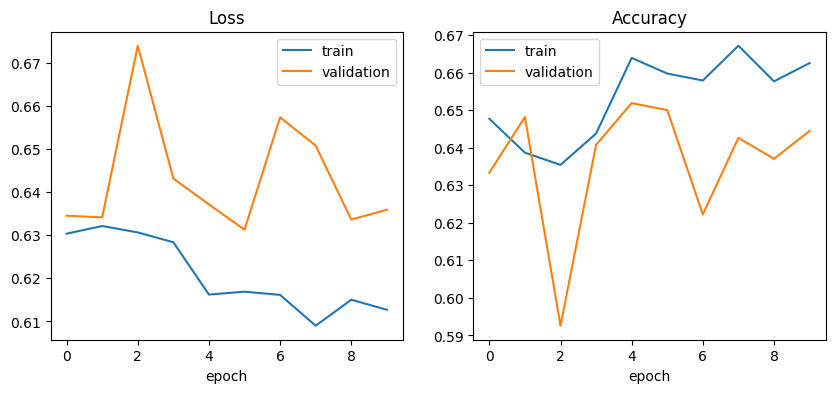

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="validation")
ax[0].set_title("Loss")
ax[1].plot(history["train_acc"], label="train")
ax[1].plot(history["val_acc"], label="validation")
ax[1].set_title("Accuracy")
for a in ax:
    a.set_xlabel("epoch")
    a.legend()
plt.show()

### 3.8 Fine-tune the last block

The model with only the last layer training was limited. Now we also let the last block of ResNet18 (`layer4`) learn, starting from the best model saved before. We use a smaller learning rate so the pretrained weights change slowly. The result is saved as a separate model.

In [15]:
model.load_state_dict(torch.load("resnet18_best.pt", map_location=device))   # start from the best frozen model

for param in model.layer4.parameters():
    param.requires_grad = True                       # unfreeze the last block of ResNet18

params = list(model.layer4.parameters()) + list(model.fc.parameters())
optimizer = torch.optim.Adam(params, lr=0.0001)      # smaller steps, so the pretrained weights change gently
EPOCHS = 8

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters now:", trainable)

history_ft = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_recall": []}
best_val_loss = 999

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch()
    val_loss, val_acc, val_recall = evaluate(val_loader)
    history_ft["train_loss"].append(train_loss)
    history_ft["val_loss"].append(val_loss)
    history_ft["train_acc"].append(train_acc)
    history_ft["val_acc"].append(val_acc)
    history_ft["val_recall"].append(val_recall)
    print(f"Epoch {epoch:2d} | train loss {train_loss:.3f} acc {train_acc:.3f} | val loss {val_loss:.3f} acc {val_acc:.3f} recall {val_recall:.3f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "resnet18_finetuned.pt")
        print("         saved best model so far")

Trainable parameters now: 8394241
Epoch  1 | train loss 0.664 acc 0.593 | val loss 0.708 acc 0.561 recall 0.930
         saved best model so far
Epoch  2 | train loss 0.607 acc 0.668 | val loss 0.655 acc 0.656 recall 0.754
         saved best model so far
Epoch  3 | train loss 0.597 acc 0.666 | val loss 0.756 acc 0.602 recall 0.404
Epoch  4 | train loss 0.571 acc 0.688 | val loss 0.654 acc 0.704 recall 0.676
         saved best model so far
Epoch  5 | train loss 0.530 acc 0.731 | val loss 0.664 acc 0.680 recall 0.555
Epoch  6 | train loss 0.517 acc 0.734 | val loss 0.661 acc 0.707 recall 0.835
Epoch  7 | train loss 0.478 acc 0.763 | val loss 0.703 acc 0.652 recall 0.893
Epoch  8 | train loss 0.465 acc 0.778 | val loss 0.763 acc 0.685 recall 0.761


Fine-tuning gave slightly better validation accuracy (about 70% compared to 65% before), but the best validation loss (0.654) is not better than before (0.631). After epoch 4 the training loss kept going down while the validation loss went up, so the model started to overfit. Epoch 4 is saved as the best model (accuracy 0.704, recall 0.676). Validation recall changes a lot between epochs (0.40 to 0.93), so we will choose the cut-off next .

## Step 4 · Evaluate on the test set
Now I use the test images for the first time. I load both saved models (frozen and fine-tuned) and get their probabilities. Nothing is trained here.

In [16]:
def load_model(path):
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 1)
    m.load_state_dict(torch.load(path, map_location=device))
    return m.to(device).eval()

def predict(m, loader):
    probs = []
    with torch.no_grad():
        for xb, _ in loader:
            out = m(xb.to(device)).squeeze(1)
            probs.append(torch.sigmoid(out).cpu().numpy())     # score -> probability of cancer (0 to 1)
    return np.concatenate(probs)

files = {"frozen": "resnet18_best.pt", "finetuned": "resnet18_finetuned.pt"}
val_probs, test_probs = {}, {}
for name, file in files.items():
    m = load_model(file)
    val_probs[name] = predict(m, val_loader)
    test_probs[name] = predict(m, test_loader)
    print(name, "done")

frozen done
finetuned done


### 4.2 Choose the cut-off on validation
Recall matters most here, so I choose the cut-off that finds at least 80% of the cancers on the validation set. I do it on validation so the test set stays untouched.

In [17]:
TARGET_RECALL = 0.80       # we want to find at least 80% of the cancers

def pick_cutoff(y, p, target):
    # go from a strict cut-off down to a loose one, stop at the first one that finds enough cancers
    for t in np.arange(0.99, 0, -0.01):
        recall = ((p >= t) & (y == 1)).sum() / (y == 1).sum()
        if recall >= target:
            return round(t, 2)
    return 0.5

cutoff = {name: pick_cutoff(y_val, val_probs[name], TARGET_RECALL) for name in files}

for name in files:
    pred = val_probs[name] >= cutoff[name]
    recall = (pred & (y_val == 1)).sum() / (y_val == 1).sum()
    precision = (pred & (y_val == 1)).sum() / pred.sum()
    print(f"{name}: cut-off {cutoff[name]} | validation recall {recall:.3f} | validation precision {precision:.3f}")

frozen: cut-off 0.41 | validation recall 0.827 | validation precision 0.595
finetuned: cut-off 0.43 | validation recall 0.801 | validation precision 0.655


I chose the cut-off on the validation set so that at least 80% of the cancers are found. The frozen model needs 0.41 and the fine-tuned one 0.43. Both are below 0.5, which means the model has to be more willing to say "cancer".

### 4.3 Results on the test set
Accuracy, precision, recall, F1 and ROC-AUC for both models, at the normal cut-off (0.5) and at the cut-off chosen above.

In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def scores(y, p, t):
    pred = (p >= t).astype(int)
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "roc_auc": roc_auc_score(y, p),
    }

rows = []
for name in files:
    rows.append({"model": name, "cut-off": 0.5, **scores(y_test, test_probs[name], 0.5)})
    rows.append({"model": name, "cut-off": cutoff[name], **scores(y_test, test_probs[name], cutoff[name])})

results = pd.DataFrame(rows).round(3)
results.to_csv("dl_results.csv", index=False)
results

,model,cut-off,accuracy,precision,recall,f1,roc_auc
0,frozen,0.50,0.613,0.608,0.654,0.630,0.640
1,frozen,0.41,0.626,0.592,0.831,0.691,0.640
2,finetuned,0.50,0.665,0.649,0.728,0.686,0.703
3,finetuned,0.43,0.630,0.598,0.809,0.688,0.703


The fine-tuned model is better overall (ROC-AUC 0.703 vs 0.640). On the test set the chosen cut-offs gave recall 0.831 (frozen) and 0.809 (fine-tuned), almost the same as on validation, so the cut-off works on new images. The price is precision, which dropped to about 0.60, so around 4 in 10 cancer predictions are false alarms. Even at this cut-off about 1 in 5 cancers is still missed. The results are modest and the model is not good enough for real medical use.

### 4.4 Confusion matrices
How many images fall in each box, at the chosen cut-off. The bottom-left box is missed cancers.

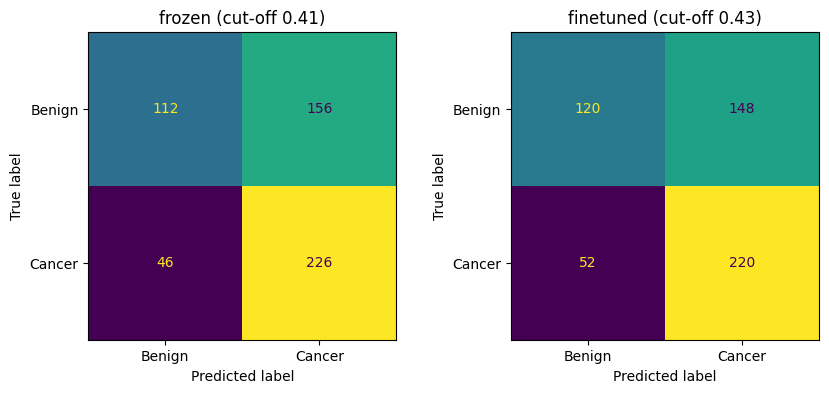

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, name in zip(ax, files):
    pred = (test_probs[name] >= cutoff[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Benign", "Cancer"], ax=a, colorbar=False)
    a.set_title(f"{name} (cut-off {cutoff[name]})")
plt.show()

At cut-off 0.43 the fine-tuned model catches 220 of 272 cancers and misses 52. It also flags 148 of 268 benign images as cancer. The frozen model is similar (46 missed, 156 false alarms). So finding most cancers costs a lot of false alarms.

### 4.5 ROC curves
Shows how well each model separates cancer from benign at every possible cut-off. The dashed line is guessing.

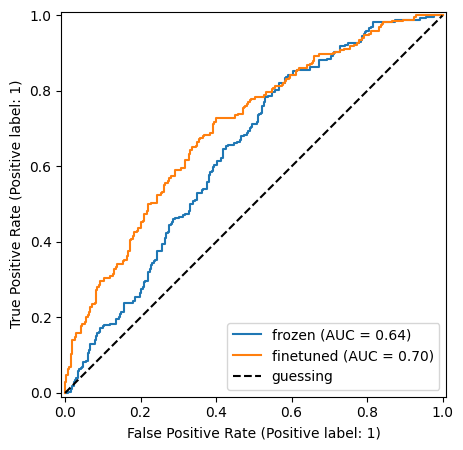

In [26]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(5, 5))
for name in files:
    RocCurveDisplay.from_predictions(y_test, test_probs[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="guessing")
ax.legend()
plt.show()

The fine-tuned curve is above the frozen one for most of the range (AUC 0.70 vs 0.64). Both are well above guessing but still far from a good classifier.

### 4.6 Save the predictions
I save the probabilities so the classical ML notebook can compare all models on the same images.

In [27]:
for split, probs in [("val", val_probs), ("test", test_probs)]:
    out = df[df.split == split].copy()
    for name in files:
        out["p_" + name] = probs[name]
    out.to_csv(f"dl_predictions_{split}.csv", index=False)
    print("saved", f"dl_predictions_{split}.csv", len(out), "rows")

saved dl_predictions_val.csv 540 rows
saved dl_predictions_test.csv 540 rows


### 4.7 Look at the mistakes
Five cancers the model missed and five benign images it called cancer, for the better model.

Model used: finetuned


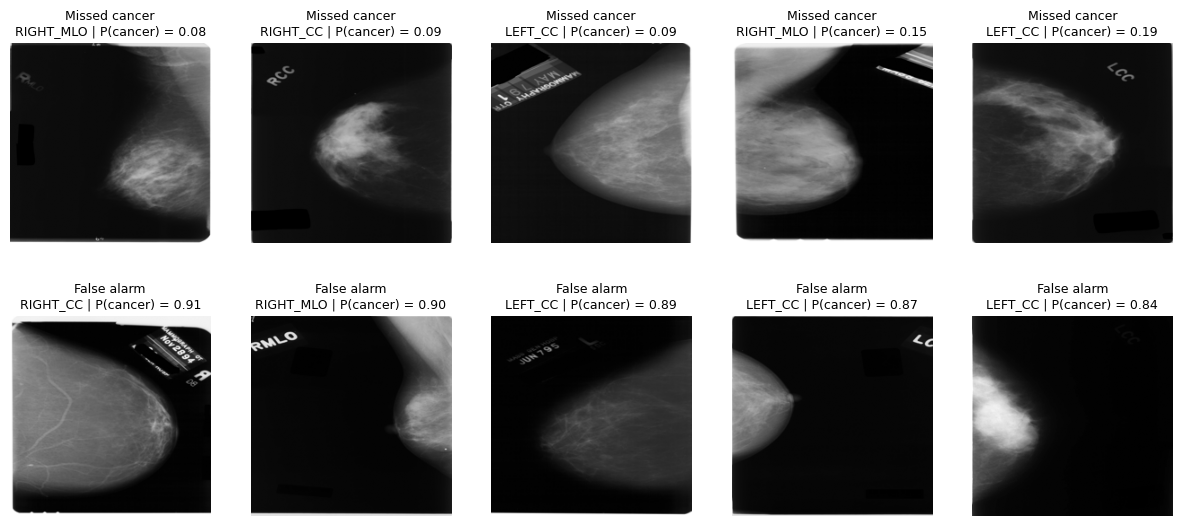

In [32]:
# using the model that had the better ROC-AUC on validation
best = max(files, key=lambda n: roc_auc_score(y_val, val_probs[n]))
print("Model used:", best)

test_df = df[df.split == "test"].reset_index(drop=True)
test_df["prob"] = test_probs[best]
test_df["pred"] = (test_df.prob >= cutoff[best]).astype(int)

missed = test_df[(test_df.label == 1) & (test_df.pred == 0)].sort_values("prob").head(5)                    # cancers with the lowest score
false_alarms = test_df[(test_df.label == 0) & (test_df.pred == 1)].sort_values("prob", ascending=False).head(5)   # benign with the highest score

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for row, (title, part) in enumerate([("Missed cancer", missed), ("False alarm", false_alarms)]):
    for col, (i, r) in enumerate(part.iterrows()):
        axes[row, col].imshow(x_test[i], cmap="gray")
        axes[row, col].set_title(f"{title}\n{r['view']} | P(cancer) = {r.prob:.2f}", fontsize=9)
    for a in axes[row]:
        a.axis("off")
plt.savefig("error_examples.png", dpi=150, bbox_inches="tight")
plt.show()

I looked at the 5 most confident mistakes of each kind. The missed cancers come from both views (CC and MLO) and have very low scores (0.08 to 0.19), so the model was quite sure they were benign. The false alarms have high scores (0.84 to 0.91). Some of these images are very dense or have film labels and date stamps on them, so the model may be reacting to things other than the tumour. With only 10 images I can't say this for sure, it is just what I noticed. The missed cancers tend to be darker, low-contrast images, and the false alarms may tend to be bright or dense.